In [ ]:
# y = 2x , 
# y= x
# y = 2x 
# y = 3x

In [25]:
x = [1,2,3,4,5]
y = [2,4,6,8,15]
print("x:", x)
print("y:", y)

x: [1, 2, 3, 4, 5]
y: [2, 4, 6, 8, 15]


In [26]:
theta = [-5,-4,-3,-2,-1,0,1,2,3,4,5]
# 1/2*m sum((y_pred - y)**2)
j_ = []


In [27]:
for i in theta:
    y_pred = [i*j for j in x]
    loss = 1/(2*len(x)) * sum([(y_pred[j] - y[j])**2 for j in range(len(y))])
    j_.append(loss)
    print(f"Theta: {i}, Loss: {loss}")




Theta: -5, Loss: 307.0
Theta: -4, Loss: 230.5
Theta: -3, Loss: 165.0
Theta: -2, Loss: 110.5
Theta: -1, Loss: 67.0
Theta: 0, Loss: 34.5
Theta: 1, Loss: 13.0
Theta: 2, Loss: 2.5
Theta: 3, Loss: 3.0
Theta: 4, Loss: 14.5
Theta: 5, Loss: 37.0


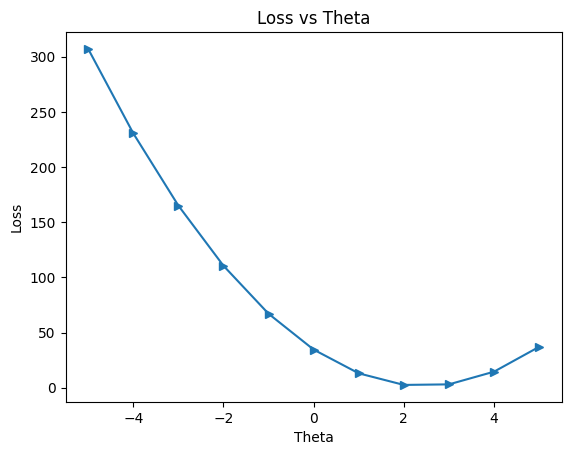

In [28]:
import matplotlib.pyplot as plt

plt.plot(theta, j_, marker = '>')
plt.xlabel("Theta")
plt.ylabel("Loss")
plt.title("Loss vs Theta")
plt.show()

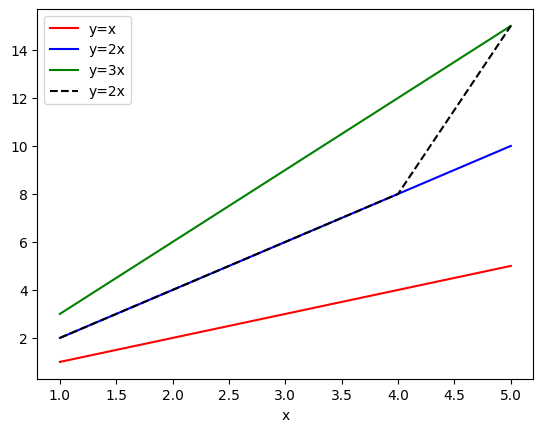

In [30]:

plt.plot(x, [1*i for i in x], label="y=x", color= 'red') # theta = 1
plt.plot(x, [2*i for i in x], label="y=2x", color= 'blue') # theta = 2 
plt.plot(x, [3*i for i in x], label="y=3x", color= 'green') # theta = 3
plt.plot(x, y, label="y=2x", color= 'black', linestyle='dashed')
plt.xlabel("x")
plt.legend()

## Regularization: Ridge & Lasso pull theta back toward 2
The point (5, 15) is an outlier (true pattern is y = 2x). Plain MSE picks theta ≈ 2.45 to chase it.
Adding a penalty on theta makes large theta costly, so the best theta moves back toward 2.

- Ridge: `loss + lambda/(2m) * theta^2`
- Lasso: `loss + lambda * |theta|`

In [ ]:
import numpy as np
m = len(x)
lam_ridge = 12.5   # ridge strength -> best theta ~ 2.0
lam_lasso = 5      # lasso strength -> best theta ~ 2.0

theta_grid = np.linspace(0, 5, 501)
xa, ya = np.array(x), np.array(y)

mse   = np.array([1/(2*m)*np.sum((t*xa - ya)**2) for t in theta_grid])
ridge = mse + lam_ridge/(2*m) * theta_grid**2
lasso = mse + lam_lasso * np.abs(theta_grid)

for name, curve in [("No regularization", mse), ("Ridge", ridge), ("Lasso", lasso)]:
    print(f"{name:18s} best theta = {theta_grid[curve.argmin()]:.2f}")

In [ ]:
plt.figure(figsize=(8,5))
for name, curve, c in [("MSE (no penalty)", mse, 'black'), ("Ridge", ridge, 'blue'), ("Lasso", lasso, 'green')]:
    plt.plot(theta_grid, curve, label=name, color=c)
    plt.scatter(theta_grid[curve.argmin()], curve.min(), color=c, zorder=5)
plt.axvline(2, color='red', linestyle='--', label='true theta = 2')
plt.xlabel("Theta"); plt.ylabel("Loss"); plt.title("Regularization moves best theta from ~2.45 to ~2")
plt.legend(); plt.show()

In [ ]:
# Error against the TRUE pattern y = 2x (clean points + unseen x=6,7) -> lower error with regularization
x_true = np.array([1,2,3,4,5,6,7]); y_true = 2*x_true
for name, curve in [("No regularization", mse), ("Ridge", ridge), ("Lasso", lasso)]:
    t = theta_grid[curve.argmin()]
    err = np.mean((t*x_true - y_true)**2)
    print(f"{name:18s} theta = {t:.2f}  error vs true line = {err:.3f}")

In [35]:
import pandas as pd
import seaborn as sns
df = pd.read_csv("../data/insurance.csv")

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [37]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


<Axes: xlabel='age', ylabel='charges'>

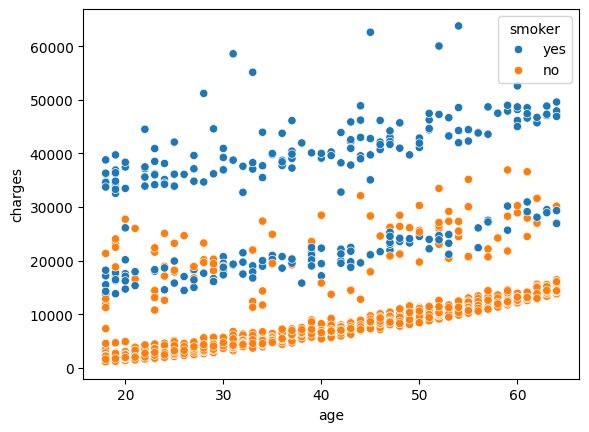

In [39]:
sns.scatterplot(data=df, x="age", y="charges", hue="smoker")

In [40]:
df.dtypes

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

In [44]:
X = df.drop(columns=["charges","region"])
y = df["charges"]

In [45]:
X.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker'], dtype='object')

In [48]:
X["sex"] = X["sex"].map({"male":0, "female":1})
X["smoker"] = X["smoker"].map({"yes":1, "no":0})

In [49]:
X.dtypes

age           int64
sex           int64
bmi         float64
children      int64
smoker        int64
dtype: object

In [50]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [51]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [52]:
y_pred = model.predict(X_test)

In [53]:
X_test.head()

,age,sex,bmi,children,smoker
764,45,1,25.175,2,0
887,36,1,30.020,0,0
890,64,1,26.885,0,1
1293,46,0,25.745,3,0
259,19,0,31.920,0,1


In [54]:
X_test['actual'] = y_test
X_test['predicted'] = y_pred

In [55]:
X_test.head()

,age,sex,bmi,children,smoker,actual,predicted
764,45,1,25.175,2,0,9095.06825,8516.761620
887,36,1,30.020,0,0,5272.17580,6893.859056
890,64,1,26.885,0,1,29330.98315,36776.198772
1293,46,0,25.745,3,0,9301.89355,9464.380662
259,19,0,31.920,0,1,33750.29180,26789.922546


In [56]:
print(model.coef_)
print(model.intercept_)

[  260.03578967   -66.06974502   327.55999306   434.80431165
 23628.2381829 ]
-12234.710618819903


In [58]:
X_test['manual_predicted'] = model.intercept_ + model.coef_[0]*X_test['age'] + model.coef_[1]*X_test['sex'] + model.coef_[2]*X_test['bmi'] + model.coef_[3]*X_test['children'] + model.coef_[4]*X_test['smoker']

In [59]:
X_test.head()

,age,sex,bmi,children,smoker,actual,predicted,manual_predicted
764,45,1,25.175,2,0,9095.06825,8516.761620,8516.761620
887,36,1,30.020,0,0,5272.17580,6893.859056,6893.859056
890,64,1,26.885,0,1,29330.98315,36776.198772,36776.198772
1293,46,0,25.745,3,0,9301.89355,9464.380662,9464.380662
259,19,0,31.920,0,1,33750.29180,26789.922546,26789.922546
